# Projeto Final da Disciplina de Análise de Dados
**Tema 6: Detecção de Adimplência / Subscrição em Telemarketing Bancário (Bank Marketing)**  

---

## 1. Estabelecimento do Problema de Negócio

### Contexto e Motivação
Uma instituição financeira bancária de Portugal realiza campanhas de marketing direto por meio de contatos telefônicos (telemarketing) visando oferecer a clientes correntistas a contratação de um produto de investimento: o **depósito a prazo fixo (*term deposit*)**. 

Campanhas de telemarketing envolvem altos custos operacionais (equipe de operadores, infraestrutura telefônica, tempo de triagem) e geram desgaste na relação com o cliente em caso de abordagens invasivas e desinteressantes.

### Objetivo do Projeto
Desenvolver e comparar modelos preditivos de *Machine Learning* para classificar se um determinado cliente contatado irá subscrever o depósito a prazo (variável dependente `y`).

A solução tem como metas centrais de negócio:
1. **Otimização Operacional:** Identificar previamente os clientes com maior propensão de compra para direcionar os contatos da equipe de vendas.
2. **Redução de Custos:** Diminuir significativamente as ligações improdutivas (falsos alarmes) feitas a clientes desinteressados.
3. **Calibração Estratégica do Modelo:** Ajustar o limiar de decisão (*decision threshold*) para lidar com o forte desbalanceamento natural da base de clientes, tornando o modelo mais criterioso e rigoroso para maximizar a precisão das abordagens.

**Obs** Os dados do dataset utilizado nesse pipeline são referentes a dados de campanhas de telemarketing de uma instituição portuguesa durante o período de 2008 a 2010

## 2. Carga do Dataset e Importação de Bibliotecas

Importamos as bibliotecas fundamentais para manipulação vetorial e estruturação de dados (`numpy` e `pandas`). Carregamos o conjunto de dados bruto a partir do arquivo `dados/bank-additional-full.csv`, utilizando o separador ponto e vírgula (`;`), característico do repositório original da **UCI Machine Learning Repository** (*Bank Marketing Dataset*).

In [66]:
import pandas as pd
import numpy as np

df_main = pd.read_csv("dados/bank-additional-full.csv", sep=";")

### Inspeção Estrutural do Conjunto de Dados
Avaliamos as características estruturais do DataFrame carregado: tipos de atributos primitivos (`info`), pré-visualização das primeiras linhas (`head`) e o volume total de registros e colunas (`shape`). O dataset contém originalmente 41.188 registros e 21 variáveis.

In [67]:
df_main.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [68]:
df_main.head(23)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
5,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
6,59,admin.,married,professional.course,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
7,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
8,24,technician,single,professional.course,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
9,25,services,single,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [69]:
df_main.shape

(41188, 21)

## 3. Análise Exploratória de Dados (EDA)

### 3.1. Verificação de Dados Ausentes (*Missing Values*)
Realizamos a contagem de valores nulos no DataFrame. O dataset não possui valores nulos no formato nativo (`NaN`), pois valores ausentes em variáveis categóricas foram registrados pelo banco com o rótulo de texto `"unknown"`. 

Em seguida, separamos as variáveis por tipo:
- **`cols_num`:** Atributos numéricos contínuos e discretos (ex: `age`, `campaign`, índices econômicos).
- **`cols_quant`:** Atributos qualitativos/categóricos textuais (ex: `job`, `marital`, `education`, `poutcome`).

In [70]:
# Nesse dataset não existem colunas com dados vazios, isso é algo bom, pois simplifica o nosso trabalho aqui
df_main.isna().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [71]:
# Separando colunas numéricas das categóricas
cols_num = df_main.dtypes[(df_main.dtypes != "object")].index
cols_quant = df_main.dtypes[(df_main.dtypes == "object")].index

### 3.2. Análise Descritiva e Identificação de Outliers
Inspecionamos os valores únicos da variável categórica `contact` e geramos o resumo estatístico (`describe`) das variáveis numéricas (média, desvio padrão, valores mínimo e máximo e quartis) para identificar dispersões atípicas.

In [72]:
df_main["contact"].unique()

array(['telephone', 'cellular'], dtype=object)

In [73]:
df_main[cols_num].describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [74]:
# df_main[""].unique()

### Detecção de Outliers na Variável `campaign`
Avaliamos a distribuição do número de contatos efetuados com cada cliente durante a presente campanha (`campaign`). O diagrama de caixa (*boxplot*) revela que 75% dos clientes receberam até 3 ligações, mas existem casos pontuais que receberam mais de 50 contatos.

<Axes: >

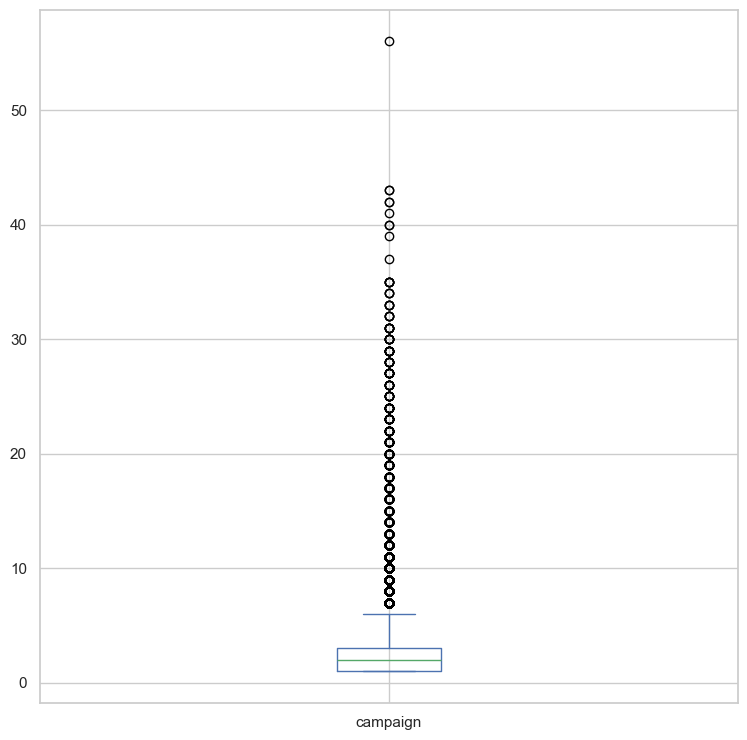

In [75]:
# Com base na nossa verificação, foi possível ver que existem prováveis outliers, 
# sendo assim, podemos observá-los na coluna campaign onde o 75% dos clientes 
# foram contactados até 3 vezes e o máximo foi de 56 vezes, sendo um possível indicador de outlier
# A coluna duration também possui prováveis outliers, mas que não serão tratados, pois essa coluna será deletada,
# uma vez, que o próprio site que disponibiliza o dataset recomenda a sua exclusão para situação de machine learning
# por ela influenciar demais os resultados e fazer com que o modelo seja irrealista
# Quanto a idade, 98 anos, apontado como valor máximo, apesar de ser alto, pode ser considerado um valor real
df_main["campaign"].plot(kind="box", figsize=(9,9 ))




In [76]:
# Levando em conta que o número de ligações recebidas, disponibilizada na coluna campaign, 
# não é referente ao período de 2008 a 2010, mas sim de campanhas específicas, podemos dizer 
# e pelo alta diferença de valores já que 75% dos dados representam 3 ligações e e outros valores acima
# remover os valores maiores que 3 poderia afetar o aprendizado do modelo, com isso, achamos que a melhor
# tratativa é categorizar os dados, para um aprendizado maior evitando valores descrepantes, mas possíveis.
# Então criamos as seguintes categorias:
# 1 a 3	 -> Pouca insistência
# 4 a 10 ->	Média insistência
# 11 a 25 -> Alta insistência
# Acima de 25 -> Insistência extrema
# Deixando a campanha como númerica
# df_main['campaign'] = pd.cut(
#     df_main['campaign'],
#     bins=[0, 3, 10, 25, float('inf')],
#     labels=[
#         'low',
#         'medium',
#         'high',
#         'extreme'
#     ]
# )

### Decisão Metodológica sobre a Variável `campaign`
Após análise teórica e testes empíricos, definimos a estratégia para a coluna `campaign`:
1. **Veracidade Histórica:** Como o dataset engloba dados de 2008 a 2010 (período da crise financeira global e agressividade bancária na captação de depósitos), as ligações frequentes refletem a realidade operacional da época e não erros de digitação.
2. **Representação Numérica vs Categórica:** Testou-se a discretização da variável em faixas de insistência (*low, medium, high, extreme*). Contudo, observou-se que manter a variável em formato numérico contínuo permitiu aos modelos (regressão e árvores) capturar um gradiente preditivo mais refinado, alcançando melhor poder de discriminação. A variável foi mantida como numérica para posterior padronização.

### 3.3. Tratamento Crítico da Variável `duration` (Prevenção de *Data Leakage*)
A coluna `duration` registra a duração da chamada telefônica em segundos. Conforme advertência expressa da documentação oficial do repositório UCI (*Moro et al., 2014*):

> *"O atributo de duração afeta fortemente o resultado alvo (por exemplo, se a duração da chamada for 0 segundos, então y = 'no'). No entanto, essa duração só é conhecida **após** a ligação ser finalizada. Portanto, deve ser descartada caso o objetivo seja construir um modelo preditivo realista."*

Manter a coluna criaria um severo **vazamento de dados (*data leakage*)**, gerando métricas artificialmente perfeitas em ambiente de teste, mas tornando o modelo inútil para prever com antecedência a quem o banco deve ligar. Por essa razão, a coluna `duration` é prontamente removida.

In [77]:
# Removendo a coluna duration por recomendação do site
df_main.pop("duration")

0        261
1        149
2        226
3        151
4        307
        ... 
41183    334
41184    383
41185    189
41186    442
41187    239
Name: duration, Length: 41188, dtype: int64

### 3.4. Tratamento da Variável `pdays` (Discretização por Faixas Temporais)
A coluna `pdays` indica a quantidade de dias desde o último contato com o cliente em campanhas passadas. O código especial **999** representa clientes que **nunca foram contatados anteriormente**.

Manter o valor numérico 999 em conjunto com valores pequenos (de 0 a 27) geraria distorções severas de escala e cálculo de distância. Por isso, a coluna foi categorizada em faixas temporais bem delineadas:
- **`recent` (0 a 7 dias):** Contatado há poucos dias em campanha recente.
- **`old` (8 a 27 dias):** Contatado anteriormente, mas há mais tempo.
- **`never` (999):** Nunca foi contatado em campanhas anteriores.

In [78]:
# Outro ponto é a coluna pdays, ela indica número de dias decorridos desde o último contato com o cliente em uma campanha anterior (numérico; 999 significa que o cliente não foi contatado anteriormente)
# Sendo assim se mantermos o 999 no dataset isso vai acabar atrapalhando a aprendizagem dos nossos modelos
df_main["pdays"].unique()

array([999,   6,   4,   3,   5,   1,   0,  10,   7,   8,   9,  11,   2,
        12,  13,  14,  15,  16,  21,  17,  18,  22,  25,  26,  19,  27,
        20])

In [79]:
# Para isso a ideia é que categorizar essa coluna para um melhor desempenho para depois aplicar onehotencoder
df_main["pdays"] = pd.cut(
    df_main["pdays"],
    bins=[-1, 7, 27, 999],
    labels=["recent", "old", "never"]
)
# Para realizar a categorização chegamos as seguintes colunas: 
# recent -> 0 a 7 dias: Quando o cliente foi contatado entre 0 a 7 dias desde a última campanha
# old -> 8 a 27 dias: Quando o cliente foi contatado entre 8 a 27 dias desde a última campanha
# never -> 999: O código 999 significa que o cliente nunca foi contatado

In [80]:
df_main["education"].unique()

array(['basic.4y', 'high.school', 'basic.6y', 'basic.9y',
       'professional.course', 'unknown', 'university.degree',
       'illiterate'], dtype=object)

### 3.5. Análise de Multicolinearidade e Variáveis Redundantes
Calculamos a matriz de correlação de Pearson entre as variáveis numéricas para detectar multicolinearidade severa ($|r| > 0,90$). A verificação aponta uma correlação expressiva entre as variáveis macroeconômicas **`euribor3m`** (taxa média de juros interbancária da Zona do Euro a 3 meses) e **`nr.employed`** (número de empregados em Portugal no indicador trimestral).

In [81]:
# Verificando dados redundantes
correlacao = df_main.corr(numeric_only=True).abs()

matriz_superior = correlacao.where(
    np.triu(np.ones(correlacao.shape), k=1).astype(bool)
)

variaveis_redundantes = [
    coluna
    for coluna in matriz_superior.columns
    if any(matriz_superior[coluna] > 0.90)
]

print(variaveis_redundantes)

['euribor3m', 'nr.employed']


In [82]:
# df_main = df_main.drop(columns="nr.euribor3m")

### Decisão Técnica sobre `euribor3m` e `nr.employed`
Embora apresentem correlação matemática alta, trata-se de índices econômicos de naturezas distintas: a Euribor dita a atratividade das taxas de juros média que os principais bancos da Zona Euro cobram entre si quando emprestam dinheiro uns aos outros no mercado interbancário, enquanto o contingente de empregados indica o número de empregados, utilizando o indicador trimestral, em Portugal durante aquele período.

**Testes de Remoção Executados:**
- A remoção de `nr.employed` manteve o desempenho geral equilibrado.
- Contudo, a remoção da `euribor3m` derrubou substancialmente a precisão e o poder discriminatório dos classificadores.

Portanto, optou-se por **manter** as variáveis macroeconômicas na base, conferindo aos algoritmos capacidade plena de capturar os efeitos do cenário macroeconômico na decisão de poupança dos clientes.

## 4. Definição da Coluna Alvo (*Target*) e Binarização

A variável alvo do projeto é a coluna `y`, que registra a decisão final do cliente:
- `'yes'` $\rightarrow$ **1** (Cliente contratou o depósito a prazo fixo - Classe Positiva)
- `'no'` $\rightarrow$ **0** (Cliente recusou a contratação - Classe Negativa)

Executamos o mapeamento binário e verificamos a integridade dos dados.

In [83]:
# Verificando o dataset
df_main.head(23)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,never,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,never,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,never,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,never,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,never,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
5,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,1,never,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
6,59,admin.,married,professional.course,no,no,no,telephone,may,mon,1,never,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
7,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,1,never,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
8,24,technician,single,professional.course,no,yes,no,telephone,may,mon,1,never,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
9,25,services,single,high.school,no,yes,no,telephone,may,mon,1,never,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [84]:
df_main['y'] = df_main['y'].map({
    'yes': 1,
    'no': 0
})

In [85]:
df_main['y'].unique()

array([0, 1])

In [86]:
# Exibindo a quantidade de colunas
print("Quantidade de colunas:", len(df_main.columns))

Quantidade de colunas: 20


In [87]:
df_main.shape

(41188, 20)

## 5. Verificação de Consistência e Remoção de Duplicatas

Garantimos que não existam colunas com nomes repetidos e verificamos a ocorrência de linhas inteiramente duplicadas no dataset. Em seguida, os registros redundantes são expurgados com `drop_duplicates()`.

In [88]:
cols_df = list(df_main.columns)
cols_duplicadas = set([i for i in cols_df if cols_df.count(i) > 1])
assert len(cols_duplicadas) == 0, "Existem colunas duplicadas no dataset"


In [89]:
print("Registros duplicados:",df_main.duplicated().sum())

Registros duplicados: 1789


In [90]:
# Removendo registros duplicados 
df_main = df_main.drop_duplicates()

In [91]:
print("Registros duplicados após remoção: ", df_main.duplicated().sum())

Registros duplicados após remoção:  0


In [92]:
df_main.shape

(39399, 20)

### Análise da Taxa de Prevalência e Diagnóstico de Desbalanceamento
A taxa de prevalência representa o percentual de clientes que aceitaram a oferta (classe 1) em relação ao total

In [93]:
def calcular_prevalencia(target):
    return sum(target)/len(target)

print(f"Prevalência da classe positivo (contraram o serviço): {calcular_prevalencia(df_main['y'].values):.0%}")

Prevalência da classe positivo (contraram o serviço): 12%


### Constatação do Severo Desbalanceamento de Classes
A taxa de prevalência é de apenas **~11,26%** de casos positivos contra **~88,74%** de casos negativos (uma proporção de aproximadamente 1 para 8).


> Esse desbalanceamento é uma característica fundamental do problema de negócio. Treinar um algoritmo diretamente nessa distribuição faria com que o modelo priorizasse a classe majoritária, podendo prever simplesmente que ninguém contrata (alcançando ~89% de acurácia, mas **Recall de 0%**). Esse fato justifica as próximas duas etapas:
> 1. **Balancear** o conjunto de treino via subamostragem (50%/50%).
> 2. Utilizar um **limiar de decisão (*threshold*) mais rigoroso (0,6)** para classificar clientes positivos nas bases reais desbalanceadas.

## 6. Preparação da Aleatoriedade e Divisão dos Dados (70% / 15% / 15%)

### Metodologia de Particionamento
Para assegurar uma avaliação científica robusta, dividimos os dados em três subconjuntos independentes:
1. **Conjunto de Treinamento (70%):** Utilizado para ajustar os modelos de aprendizado.
2. **Conjunto de Validação (15%):** Utilizado para calibrar hiperparâmetros, ajustar o limiar de decisão (*threshold*) e comparar os modelos entre si.
3. **Conjunto de Teste (15%):** Mantido estritamente isolado de qualquer decisão de ajuste. Será avaliado uma única vez ao final para atestar a capacidade de generalização do modelo em novos dados do mundo real.

Antes da divisão, aplicamos embaralhamento aleatório com semente fixa (`random_state=12`) para eliminar vieses de ordenação temporal ou de coleta.

In [94]:
# Primeiro vamos criar um dataset de copia para manipular os dados sem perdemos o que já temos
df_data = df_main.copy()

In [95]:
# Embaralhando o dataset
df_data = df_data.sample(n = len(df_data), random_state=12)
df_data.head(23)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
39039,18,student,single,basic.9y,no,yes,no,cellular,dec,mon,2,never,0,nonexistent,-3.0,92.713,-33.0,0.715,5023.5,0
40038,41,admin.,divorced,university.degree,no,yes,no,cellular,jul,mon,1,old,2,success,-1.7,94.215,-40.3,0.793,4991.6,1
26611,31,blue-collar,single,high.school,no,no,no,cellular,nov,thu,1,never,0,nonexistent,-0.1,93.200,-42.0,4.076,5195.8,0
40986,84,retired,divorced,basic.4y,unknown,yes,yes,cellular,oct,mon,4,recent,1,success,-1.1,94.601,-49.5,1.000,4963.6,0
40915,74,retired,married,university.degree,no,no,no,telephone,oct,mon,1,never,0,nonexistent,-1.1,94.601,-49.5,0.977,4963.6,0
31287,59,admin.,married,high.school,no,no,no,cellular,may,wed,1,never,0,nonexistent,-1.8,92.893,-46.2,1.334,5099.1,0
9525,56,retired,married,basic.4y,no,yes,no,telephone,jun,mon,1,never,0,nonexistent,1.4,94.465,-41.8,4.961,5228.1,0
19400,37,admin.,married,university.degree,unknown,no,no,cellular,aug,wed,1,never,0,nonexistent,1.4,93.444,-36.1,4.967,5228.1,1
31222,38,blue-collar,married,basic.4y,no,no,no,cellular,may,wed,1,never,1,failure,-1.8,92.893,-46.2,1.334,5099.1,0
39177,53,admin.,divorced,university.degree,no,yes,no,telephone,mar,thu,1,never,2,failure,-1.8,93.369,-34.8,0.654,5008.7,0


In [96]:
# Reorganizando os index do dataset, já que ele foi embaralhado
df_data = df_data.reset_index(drop=True)
df_data.head(5)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,18,student,single,basic.9y,no,yes,no,cellular,dec,mon,2,never,0,nonexistent,-3.0,92.713,-33.0,0.715,5023.5,0
1,41,admin.,divorced,university.degree,no,yes,no,cellular,jul,mon,1,old,2,success,-1.7,94.215,-40.3,0.793,4991.6,1
2,31,blue-collar,single,high.school,no,no,no,cellular,nov,thu,1,never,0,nonexistent,-0.1,93.200,-42.0,4.076,5195.8,0
3,84,retired,divorced,basic.4y,unknown,yes,yes,cellular,oct,mon,4,recent,1,success,-1.1,94.601,-49.5,1.000,4963.6,0
4,74,retired,married,university.degree,no,no,no,telephone,oct,mon,1,never,0,nonexistent,-1.1,94.601,-49.5,0.977,4963.6,0


In [97]:
# Criando novos datasets de acordo com as porcentagens de treino, teste e validação
df_teste_valid = df_data.sample(frac=0.3, random_state=42)
print(f"Divisão feita com {len(df_teste_valid)/len(df_data):.1f} dos dados")

Divisão feita com 0.3 dos dados


In [98]:
# Relizando o restante das divisões
# divisão de 50% dos 30% de teste e validação para que cada um fique com 15% dos dados
df_teste = df_teste_valid.sample(frac=0.5, random_state=42)
df_valid = df_teste_valid.drop(df_teste.index)

# O restante são os dados de treino
df_treino = df_data.drop(df_teste_valid.index)


### Verificação da Prevalência em Cada Subconjunto
Comprovamos que a proporção natural de ~11% (praticamente quase 12%) de conversão foi preservada harmonicamente nos três conjuntos (treino, validação e teste), garantindo integridade amostral.

In [99]:
print(f"Taxa de prevalência no subconjunto de treino: {calcular_prevalencia(df_treino["y"].values):.2%}\nQuantidade total de linhas: {len(df_treino)}")
amostra_treino = (len(df_treino) * calcular_prevalencia(df_treino["y"].values)) 
print(f"Quantidade de registros que contraram no subconjunto de treino: {amostra_treino:.0f}")
print("----------------------")
print(f"Taxa de prevalência no subconjunto de validação: {calcular_prevalencia(df_valid['y'].values):.2%}\nQuantidade total de linhas: {len(df_valid)}")
amostra_valid = (len(df_valid) * calcular_prevalencia(df_valid["y"].values) )
print(f"Quantidade de registros que contraram no subconjunto de validação: {amostra_valid:.0f}")
print("----------------------")
print(f"Taxa de prevalência no subconjunto de teste: {calcular_prevalencia(df_teste["y"].values):.2%}\nQuantidade total de linhas: {len(df_teste)}")
amostra_teste = (len(df_teste) * calcular_prevalencia(df_teste["y"].values))
print(f"Quantidade de registros que contraram no subconjunto de testes: {amostra_teste:.0f}")

Taxa de prevalência no subconjunto de treino: 11.67%
Quantidade total de linhas: 27579
Quantidade de registros que contraram no subconjunto de treino: 3218
----------------------
Taxa de prevalência no subconjunto de validação: 11.32%
Quantidade total de linhas: 5910
Quantidade de registros que contraram no subconjunto de validação: 669
----------------------
Taxa de prevalência no subconjunto de teste: 11.96%
Quantidade total de linhas: 5910
Quantidade de registros que contraram no subconjunto de testes: 707


### Validação da Integridade Amostral Total
Confirmamos via asserção lógica que a soma exata dos registros das três partições corresponde rigorosamente ao total do dataset pré-processado.

In [100]:
print("Tamanho do dataset original:", len(df_main))

assert (len(df_main) == (len(df_valid)+len(df_teste)+len(df_treino)))

Tamanho do dataset original: 39399


## 7. Balanceamento de Dados (Subamostragem / *Undersampling* no Treino)

### Metodologia de Balanceamento
Para que os algoritmos consigam aprender com igual representatividade os padrões que diferenciam quem contrata de quem não contrata, aplicamos a técnica de **subamostragem aleatória (*random undersampling*) da classe negativa** exclusivamente sobre o conjunto de **treino**.

- O subconjunto de treino balanceado (`df_treino_balanceado`) passa a contar com **50% de positivos e 50% de negativos**.
- **Nota Metodológica Crucial:** Os conjuntos de validação e teste permanecem **intactos e desbalanceados** (~11% positivos), pois devem representar fielmente a distribuição real da carteira de clientes que o banco enfrentará na prática.

In [101]:
rows_pos = df_treino['y'] == 1

df_pos = df_treino.loc[rows_pos]

df_neg = df_treino.loc[~rows_pos]

menor = np.min([len(df_pos), len(df_neg)])

df_treino_balanceado = pd.concat([df_pos.sample(n=menor, random_state=12), df_neg.sample(n=menor, random_state=12)], axis=0, ignore_index=True)

df_treino_balanceado = df_treino_balanceado.sample(n = len(df_treino_balanceado), random_state=12).reset_index(drop=True)

print(f"Tamanho do dataset balanceado: {len(df_treino_balanceado)}\nPercentual de prevalência: {calcular_prevalencia(df_treino_balanceado["y"].values)}")


Tamanho do dataset balanceado: 6436
Percentual de prevalência: 0.5


## 8. Pré-processamento, Codificação e Normalização (Pipeline com ColumnTransformer)

### 8.1. Estruturação dos Transformadores
Construímos um pipeline unificado utilizando o `ColumnTransformer` do Scikit-Learn:
1. **One-Hot Encoding (`OneHotEncoder`):** Aplicado a todas as variáveis categóricas nominais (`cols_onehot`), com `handle_unknown='ignore'` para garantir robustez caso surjam novas categorias no futuro. O One-Hot evita atribuir uma ordem hierárquica inexistente a variáveis como profissão (`job`), estado civil (`marital`) e categorias contendo `"unknown"`.
2. **Padronização Numérica (`StandardScaler`):** Aplicada às variáveis quantitativas contínuas (`cols_num`), reescalando-as para média 0 e desvio padrão 1. Essa etapa é indispensável para a estabilidade da Regressão Linear e de modelos baseados em variância.

### 8.2. Prevenção de Data Leakage
O método `.fit_transform()` é aplicado **apenas sobre o conjunto de treino balanceado**. Os conjuntos de validação e teste recebem unicamente o método `.transform()`, assegurando que médias e desvios não vazem de uma base para outra.

In [102]:
# Visando aplicar o OneHot e o Ordinal Encode a ideia de separação é a seguinte:
# OneHot Encode: job, maritial, default, housing, loan, contact, month, day_of_week, poutcome, education
# Colunas como: default, housing, loan, poutcome e education foram escolhidas para o OneHot Encode, apesar de terem um hierarquia, elas possuem colunas unknow (desconhecido) e quando aplicado o Ordinal Encode isso se torna um problema, pois esse tipo de categoria pode receber uma nota alta, fazendo com que as equações feitas pelo modelo não sejam robustas

# Selecionando colunas para aplicar o OneHot Encode
cols_onehot = df_treino_balanceado.select_dtypes(include=['object', 'category']).columns.tolist()
if 'campaign' in cols_onehot:
    cols_onehot.remove('campaign')
cols_num = df_treino_balanceado.select_dtypes(include=["int64", "float"]).columns.to_list()
if 'y' in cols_num:
    cols_num.remove('y')
# col_ordinal = ["campaign"]
# ordem_cat = [["low", "medium", "high", "extreme"]]

print(cols_onehot)
print(cols_num)
# print(col_ordinal)
# print(ordem_cat)


['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'pdays', 'poutcome']
['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


In [103]:
df_treino.to_csv("dados/df_treino.csv", index=False, encoding="utf-8")
df_valid.to_csv("dados/df_valid.csv", index=False, encoding="utf-8")
df_teste.to_csv("dados/df_teste.csv", index=False, encoding="utf-8")

In [104]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler


preprocessor = ColumnTransformer(
    transformers=[
        # O parâmetro handle_unknown='ignore' evita erros se o modelo esbarrar
        # em uma categoria nos dados de teste que não existia no treino
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cols_onehot),
        # ('ordinal', OrdinalEncoder(categories=ordem_cat), col_ordinal),
        ("scaler", StandardScaler(), cols_num)
    ],
    remainder='drop' # Mantém as outras colunas (como age e campaign) intactas
)

y_treino = df_treino_balanceado["y"].values
df_treino_balanceado = df_treino_balanceado.drop(columns="y")




In [105]:
X_treino = preprocessor.fit_transform(df_treino_balanceado)


In [106]:
X_treino.shape

(6436, 63)

In [107]:
type(y_treino[0])

numpy.int64

In [108]:
X_treino

array([[ 1.        ,  0.        ,  0.        , ..., -1.29576064,
        -0.83357262, -0.42213672],
       [ 0.        ,  0.        ,  0.        , ...,  0.70796275,
         0.99494393,  0.63627293],
       [ 0.        ,  0.        ,  0.        , ..., -0.30326214,
         1.0489731 ,  1.06355255],
       ...,
       [ 0.        ,  0.        ,  0.        , ...,  1.64428209,
        -1.10954514, -0.68587535],
       [ 0.        ,  0.        ,  0.        , ..., -0.30326214,
         1.0500325 ,  1.06355255],
       [ 1.        ,  0.        ,  0.        , ..., -0.34071491,
         0.58125001,  0.69155439]], shape=(6436, 63))

### Aplicação dos Transformadores nos Dados de Validação
Aplicamos o `preprocessor.transform()` nos dados de validação, gerando as matrizes NumPy correspondentes (`X_valid` e `y_valid`).

In [109]:
# Aplicando a mesma normalização para os dados de validação
y_valid = df_valid["y"].values
df_valid = df_valid.drop(columns="y")
X_valid = preprocessor.transform(df_valid)


In [110]:
X_valid.shape

(5910, 63)

In [111]:
X_valid

array([[ 0.        ,  0.        ,  0.        , ..., -0.30326214,
         1.0500325 ,  1.06355255],
       [ 1.        ,  0.        ,  0.        , ...,  0.76414191,
         1.05109189,  1.06355255],
       [ 0.        ,  0.        ,  0.        , ...,  0.76414191,
         1.05321068,  1.06355255],
       ...,
       [ 0.        ,  0.        ,  0.        , ..., -1.83882586,
        -0.69691061, -0.42213672],
       [ 0.        ,  1.        ,  0.        , ..., -0.47179962,
         1.0479137 ,  1.06355255],
       [ 0.        ,  1.        ,  0.        , ..., -1.12722316,
        -0.87488904, -0.42213672]], shape=(5910, 63))

## 9. Construção das Métricas de Avaliação de Modelos

### Fundamentação Teórica das Métricas
Para avaliar os modelos sob a perspectiva acadêmica e as necessidades da operação de telemarketing bancário, calculamos as seguintes métricas a partir da Matriz de Confusão:

1. **Especificidade (*True Negative Rate*):**
   $$\text{Especificidade} = \frac{VN}{VN + FP}$$
   Mede a proporção de clientes que não têm interesse e que o modelo identificou corretamente como negativos. Uma alta especificidade evita gastar recursos com ligações infrutíferas.

2. **Recall / Sensibilidade (*True Positive Rate*):**
   $$\text{Recall} = \frac{VP}{VP + FN}$$
   Mede a proporção de clientes propensos à contratação que o modelo conseguiu detectar com sucesso. Quanto maior o recall, menos vendas em potencial o banco perde.

3. **Precisão (*Positive Predictive Value*):**
   $$\text{Precisão} = \frac{VP}{VP + FP}$$
   Mede a taxa de conversão real das ligações recomendadas pelo modelo: dentre todos os clientes classificados como positivos, qual percentual efetivamente aderiu ao depósito.

4. **Acurácia Geral (*Accuracy Score*):**
   $$\text{Acurácia} = \frac{VP + VN}{VP + VN + FP + FN}$$
   Percentual total de previsões corretas. Em dados desbalanceados, deve ser analisada com cautela e sempre acompanhada de Precisão e Recall.

5. **ROC AUC (*Area Under the Receiver Operating Characteristic Curve*):**
   Mede o poder discriminatório global do algoritmo de ordenar probabilidades corretamente ao longo de todos os limiares possíveis.

In [112]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score


def calcular_especificidade(y_atual, y_pred, thresh):
    # return sum((y_pred < thresh) & (y_atual == 0) / sum(y_atual == 0))
    return np.sum((y_pred < thresh) & (y_atual == 0)) / np.sum(y_atual == 0)

def calcular_metricas(y_atual, y_pred, thresh):
    specificity = calcular_especificidade(y_atual, y_pred, thresh)
    auc = roc_auc_score(y_atual, y_pred)
    accuracy = accuracy_score(y_atual, (y_pred > thresh))
    recall = recall_score(y_atual, (y_pred > thresh))
    precision = precision_score(y_atual, (y_pred > thresh))

    print(f"Especificidade: {specificity:.3f}")
    print(f"AUC: {auc:.3f}")
    print(f"Acurácia: {accuracy:.3f}")
    print(f"Recall {recall:.3f}")
    print(f"Precisão: {precision:.3f}")
    return specificity, auc, accuracy, recall, precision


### Funções de Avaliação: `predict_proba` vs `predict`
- **`calcular_metricas`:** Utilizada para predições de probabilidade contínua geradas por `predict_proba` (ou valores da Regressão Linear), aplicando um limiar de corte ajustável (`thresh`).
- **`calcular_metricas_predict`:** Utilizada para predições discretas diretas (0 ou 1) geradas pelo método `predict` convencional, que assume internamente o ponto de corte fixo de 0,5.

In [113]:
from sklearn.metrics import confusion_matrix


def calcular_metricas_predict(y_atual, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_atual,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp)
    accuracy = accuracy_score(y_atual, y_pred)
    recall = recall_score(y_atual, y_pred)
    precision = precision_score(y_atual, y_pred)

    print(f"Especificidade: {specificity:.3f}")
    print(f"Acurácia: {accuracy:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"Precisão: {precision:.3f}")

    return specificity, accuracy, recall, precision

## 10. Justificativa Teórica e Prática do Limiar de Decisão: `thresh = 0.6`

### Por que adotar um limiar de 0,6 em vez do tradicional 0,5?
Em problemas de classificação binária, o valor padrão de corte (*threshold*) é convencionalmente fixado em $0,5$. No entanto, neste projeto acadêmico de telemarketing bancário, a escolha de **`thresh = 0.6`** é uma determinação estratégica indispensável para o sucesso do modelo no mundo real, justificada pelos seguintes fatores fundamentais:

#### 1. A Mudança de Distribuição entre Treino e Realidade Operacional
- O modelo foi treinado em uma base de dados artificialmente **balanceada em 50% / 50%**. Isso significa que as funções de probabilidade dos algoritmos foram ajustadas assumindo que a probabilidade a priori de alguém contratar o depósito é de 50%.
- Porém, no conjunto de validação, de teste e na carteira real de clientes do banco, a taxa de sucesso natural é de apenas **~11% de casos positivos** contra **~89% de casos negativos** (quase 8 clientes desinteressados para cada cliente interessado).

#### 2. O Risco Crítico de Falsos Positivos com o Limiar de 0,5
- Se aplicarmos o corte clássico de $0,5$ sobre uma população em que 89% dos indivíduos pertencem à classe negativa, qualquer margem de dúvida do modelo se converte em um **volume massivo de Falsos Positivos** (clientes que o banco liga achando que vão contratar, mas recusam a proposta).
- Como a base de não-contratantes é esmagadora, uma pequena taxa de erro falso-positivo destrói completamente a **Precisão** do modelo (derrubando-a para patamares inaceitáveis de 20% a 30%), fazendo com que a equipe de telemarketing gaste incontáveis horas de trabalho improdutivo.

#### 3. A Necessidade de um Modelo Mais Rigoroso
- Ao calibrar o limiar de decisão para **$0,6$**, exigimos que o modelo tenha pelo menos **60% de convicção estatística** antes de emitir uma recomendação de contato para a equipe comercial.
- Esse rigor adicional gera benefícios imediatos para o negócio:
  - **Filtra e reduz drasticamente os Falsos Positivos** (evitando ligações desperdiçadas);
  - **Eleva significativamente a Precisão e a Especificidade** da operação;
  - Mantém o **Recall** em patamares excelentes e competitivos;
  - Otimiza o Custo de Aquisição de Clientes (CAC) e eleva a rentabilidade da campanha de telemarketing bancário.

In [114]:
thresh = 0.6

### Função Auxiliar para Visualização da Matriz de Confusão
Desenvolvemos uma função padronizada com o `seaborn` para gerar mapas de calor (*heatmaps*) das Matrizes de Confusão de cada modelo, permitindo visualizar com clareza a distribuição entre:
- **Verdadeiros Negativos (VN):** Clientes que não contratariam e foram previstos corretamente como 0 (economia de ligações).
- **Falsos Positivos (FP):** Clientes que não contratariam, mas foram previstos incorretamente como 1 (custo operacional de ligação perdida).
- **Falsos Negativos (FN):** Clientes que contratariam, mas o modelo não identificou (custo de oportunidade de venda perdida).
- **Verdadeiros Positivos (VP):** Clientes que contratariam e foram previstos corretamente como 1 (sucesso de conversão).

In [115]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plotar_matriz_confusao(y_real, y_pred, titulo="Matriz de Confusão", subtitulo="Conjunto de Validação"):
    cm = confusion_matrix(y_real, y_pred, labels=[0, 1])
    plt.figure(figsize=(6, 4.5))
    sns.heatmap(
        cm, 
        annot=True, 
        fmt="d", 
        cmap="Blues", 
        cbar=False,
        annot_kws={"size": 13, "weight": "bold"},
        xticklabels=["Não Contratou (0)", "Contratou (1)"],
        yticklabels=["Não Contratou (0)", "Contratou (1)"]
    )
    plt.title(f"{titulo}\n{subtitulo}", fontsize=12, pad=10)
    plt.xlabel("Previsão do Modelo", fontsize=11, fontweight="bold")
    plt.ylabel("Classe Real", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()

    tn, fp, fn, tp = cm.ravel()
    print(f"Detalhamento Numérico: VN={tn} | FP={fp} | FN={fn} | VP={tp} | Total de Casos={len(y_real)}")


## 11. Construção e Treinamento dos Modelos de Machine Learning

Para atender às diretrizes da disciplina, são construídos, avaliados e comparados três algoritmos distintos:
- **Regressão Linear (Modelo de Probabilidade Linear)**
- **Naive Bayes (GaussianNB)**
- **Random Forest Classifier (Floresta Aleatória)**

---

### 11.1. Modelo 1: Regressão Linear (*Linear Probability Model*)
A Regressão Linear tradicional é voltada para variáveis contínuas. Contudo, ao ser ajustada com um vetor dependente binário ($y \in \{0, 1\}$), atua como um Modelo de Probabilidade Linear. A previsão contínua do modelo é então binarizada através do limiar rigoroso de $0,6$ (`np.where(pred > thresh, 1, 0)`).

In [116]:
from sklearn.linear_model import LinearRegression

model_lr = LinearRegression()
model_lr.fit(X_treino, y_treino)

# Pegamos a previsão bruta (decimais) e forçamos a virar um array de inteiros (0 e 1)
y_train_preds = np.where(model_lr.predict(X_treino) > thresh, 1, 0)
y_valid_preds = np.where(model_lr.predict(X_valid) > thresh, 1, 0)

print("Métricas com os dados de treino ")
lr_train_specificity, lr_train_auc, lr_train_accuracy, lr_train_recall, lr_train_precision = calcular_metricas(y_treino, y_train_preds, thresh)
print("--------")
print("Métricas com os dados de validação ")
lr_valid_specificity, lr_valid_auc, lr_valid_accuracy, lr_valid_recall, lr_valid_precision = calcular_metricas(y_valid, y_valid_preds, thresh)

Métricas com os dados de treino 
Especificidade: 0.885
AUC: 0.731
Acurácia: 0.731
Recall 0.578
Precisão: 0.834
--------
Métricas com os dados de validação 
Especificidade: 0.894
AUC: 0.729
Acurácia: 0.856
Recall 0.565
Precisão: 0.404


#### Matriz de Confusão: Regressão Linear (Validação)
Apresentamos a Matriz de Confusão obtida pela Regressão Linear no conjunto de validação sob o limiar rigoroso de $0,6$.

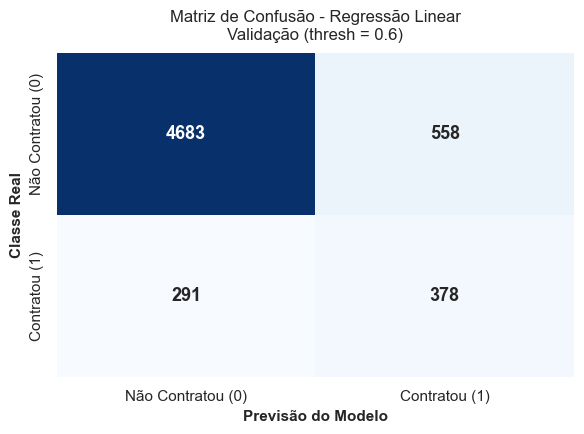

Detalhamento Numérico: VN=4683 | FP=558 | FN=291 | VP=378 | Total de Casos=5910


In [117]:
plotar_matriz_confusao(
    y_valid, 
    y_valid_preds, 
    titulo="Matriz de Confusão - Regressão Linear", 
    subtitulo=f"Validação (thresh = {thresh})"
)

### 11.2. Modelo 2: Naive Bayes (*Gaussian Naive Bayes*)
O classificador Naive Bayes fundamenta-se no Teorema de Bayes sob a premissa simplificadora de **independência condicional** entre todos os atributos. O algoritmo estima probabilidades a posteriori tanto pelo método probabilístico contínuo (`predict_proba` sujeito ao limiar rigoroso de 0,6) quanto pelo método binário direto (`predict` com limiar default de 0,5).

In [118]:
from sklearn.naive_bayes import GaussianNB

model_nb = GaussianNB()
model_nb.fit(X_treino, y_treino)

y_train_preds_predict = model_nb.predict(X_treino)
y_valid_preds_predict = model_nb.predict(X_valid)

y_train_preds_predict_prob = model_nb.predict_proba(X_treino)[:,1]
y_valid_preds_predict_prob = model_nb.predict_proba(X_valid)[:,1]

# para a função de predict dos dados de treino

print("Dados obtidos pelo método predict_proba com dados de treino")
nb_train_specificity, nb_train_auc, nb_train_accuracy, nb_train_recall, nb_train_precision = calcular_metricas(y_treino, y_train_preds_predict_prob, thresh)
print("Dados obtidos pelo método de predict_proba com dados de validação")
nb_valid_specificity, nb_valid_auc, nb_valid_accuracy, nb_valid_recall, nb_valid_precision = calcular_metricas(y_valid, y_valid_preds_predict_prob, thresh)
print("-----------")
print("Dados obtidos pelos métodos de predict com dados de treino")
nb_train_specificity_predict, nb_train_accuracy_predict, nb_train_recall_predict, nb_train_precision_predict = calcular_metricas_predict(y_treino, y_train_preds_predict)
print("Dados obtidos pelos métodos de predict com os dados de validação")
nb_valid_specificity_predict, nb_valid_accuracy_predict, nb_valid_recall_predict, nb_valid_precision_predict = calcular_metricas_predict(y_valid, y_valid_preds_predict)

Dados obtidos pelo método predict_proba com dados de treino
Especificidade: 0.902
AUC: 0.768
Acurácia: 0.681
Recall 0.460
Precisão: 0.825
Dados obtidos pelo método de predict_proba com dados de validação
Especificidade: 0.907
AUC: 0.769
Acurácia: 0.858
Recall 0.477
Precisão: 0.394
-----------
Dados obtidos pelos métodos de predict com dados de treino
Especificidade: 0.897
Acurácia: 0.685
Recall: 0.473
Precisão: 0.820
Dados obtidos pelos métodos de predict com os dados de validação
Especificidade: 0.901
Acurácia: 0.854
Recall: 0.489
Precisão: 0.386


#### Matrizes de Confusão: Naive Bayes (Validação)
Comparamos o desempenho do Naive Bayes através de duas Matrizes de Confusão:
1. Utilizando o método probabilístico `predict_proba` com o **limiar rigoroso de $0,6$**.
2. Utilizando o método convencional `predict` (limiar padrão $0,5$).

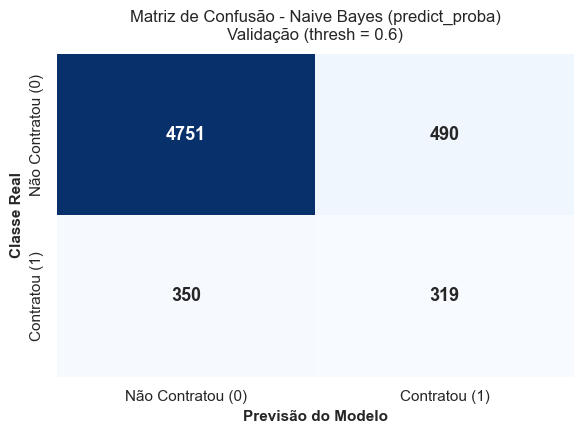

Detalhamento Numérico: VN=4751 | FP=490 | FN=350 | VP=319 | Total de Casos=5910


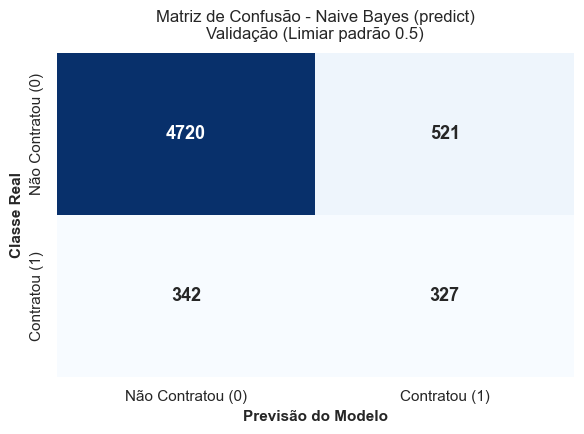

Detalhamento Numérico: VN=4720 | FP=521 | FN=342 | VP=327 | Total de Casos=5910


In [119]:
# Matriz de Confusão para Naive Bayes com thresh = 0.6 (predict_proba)
y_valid_preds_nb_thresh = np.where(y_valid_preds_predict_prob > thresh, 1, 0)
plotar_matriz_confusao(
    y_valid, 
    y_valid_preds_nb_thresh, 
    titulo="Matriz de Confusão - Naive Bayes (predict_proba)", 
    subtitulo=f"Validação (thresh = {thresh})"
)

# Matriz de Confusão para Naive Bayes com predict (limiar padrão 0.5)
plotar_matriz_confusao(
    y_valid, 
    y_valid_preds_predict, 
    titulo="Matriz de Confusão - Naive Bayes (predict)", 
    subtitulo="Validação (Limiar padrão 0.5)"
)

### 11.3. Modelo 3: Random Forest Classifier (Floresta Aleatória)

O Random Forest é um algoritmo de aprendizado baseado em conjunto (*ensemble*) que combina múltiplas árvores de decisão independentes treinadas via *bagging* e seleção aleatória de atributos.

A seguir, demonstramos a evolução do modelo em dois passos:
1. **Modelo Inicial (Sem Restrições):** Apresentando o fenômeno de sobreajuste (*overfitting*).
2. **Modelo V2 (Com Regularização):** Ajuste de hiperparâmetros para garantir generalização ideal.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

model_rf_v2 = RandomForestClassifier(n_estimators=100, random_state=12)
model_rf_v2.fit(X_treino, y_treino)

y_train_preds_predict = model_rf_v2.predict(X_treino)
y_train_preds_predict_prob = model_rf_v2.predict_proba(X_treino)[:,1]

y_valid_preds_predict = model_rf_v2.predict(X_valid)
y_valid_preds_predict_prob = model_rf_v2.predict_proba(X_valid)[:,1]


print("Métricas com dados de treino usando o predict_proba")
calcular_metricas(y_treino, y_train_preds_predict_prob, thresh)
print("Métricas com dados de validação usando o predict_proba")
calcular_metricas(y_valid, y_valid_preds_predict_prob, thresh)
print("-----------")
print("Métricas com dados de treino usando predict")
calcular_metricas_predict(y_treino, y_train_preds_predict)
print("Métricas com dados de validação usando o predict")
calcular_metricas_predict(y_valid, y_valid_preds_predict)


Métricas com dados de treino usando o predict_proba
Especificidade: 1.000
AUC: 1.000
Acurácia: 0.995
Recall 0.991
Precisão: 1.000
Métricas com dados de validação usando o predict_proba
Especificidade: 0.866
AUC: 0.779
Acurácia: 0.839
Recall 0.590
Precisão: 0.368
-----------
Métricas com dados de validação usando o predict
Especificidade: 0.799
Acurácia: 0.783
Recall: 0.659
Precisão: 0.295
Métricas com dados de treino usando predict
Especificidade: 0.998
Acurácia: 0.998
Recall: 0.998
Precisão: 0.998


(np.float64(0.997513983840895),
 0.9979801118707271,
 0.9984462399005594,
 0.997516299285936)

#### Diagnóstico de Sobreajuste (*Overfitting*) no Random Forest Inicial
No primeiro modelo executado acima, sem qualquer restrição de profundidade máxima, as árvores cresceram até isolar individualmente as amostras de treino. Isso gerou métricas perfeitas no treino (100% de acurácia e precisão), mas o desempenho desmoronou na validação, onde a precisão caiu drasticamente para cerca de **35%**.

Esse quadro reflete o clássico **overfitting**: o modelo memorizou as particularidades e ruídos da base de treino balanceada e perdeu a capacidade de generalizar para dados reais. Conforme as orientações do projeto, **não** geramos a matriz de confusão deste modelo com sobreajuste, prosseguindo diretamente para o modelo devidamente regularizado e V2.

#### Regularização e Ajuste de Hiperparâmetros do Random Forest
Para sanar o sobreajuste e conferir estabilidade estatística ao modelo, introduzimos restrições estruturais:
- `max_depth = 10`: Limita a profundidade máxima de cada árvore de decisão a 10 níveis, evitando partições excessivamente complexas.
- `min_samples_leaf = 5`: Exige que cada folha terminal contenha pelo menos 5 amostras, suavizando as previsões e prevenindo a memorização de casos isolados.

In [121]:
model_rf_v2 = RandomForestClassifier(n_estimators=100, random_state=12, max_depth=10,          # Limita a profundidade das árvores (ex: entre 8 e 15)
    min_samples_leaf=5,)
model_rf_v2.fit(X_treino, y_treino)

y_train_preds_predict = model_rf_v2.predict(X_treino)
y_train_preds_predict_prob = model_rf_v2.predict_proba(X_treino)[:,1]

y_valid_preds_predict = model_rf_v2.predict(X_valid)
y_valid_preds_predict_prob = model_rf_v2.predict_proba(X_valid)[:,1]

print("Métricas com dados de treino usando o predict_proba")
rf_train_specificity, rf_train_auc, rf_train_accuracy, rf_train_recall, rf_train_precision = calcular_metricas(y_treino, y_train_preds_predict_prob, thresh)
print("Métricas com dados de validação usando o predict_proba")
rf_valid_specificity, rf_valid_auc, rf_valid_accuracy, rf_valid_recall, rf_valid_precision = calcular_metricas(y_valid, y_valid_preds_predict_prob, thresh)
print("-----------")
print("Métricas com dados de treino usando predict")
rf_train_specificity_predict, rf_train_accuracy_predict, rf_train_recall_predict, rf_train_precision_predict = calcular_metricas_predict(y_treino, y_train_preds_predict)
print("Métricas com dados de validação usando o predict")
rf_valid_specificity_predict, rf_valid_accuracy_predict, rf_valid_recall_predict, rf_valid_precision_predict = calcular_metricas_predict(y_valid, y_valid_preds_predict)

Métricas com dados de treino usando o predict_proba
Especificidade: 0.902
AUC: 0.842
Acurácia: 0.748
Recall 0.594
Precisão: 0.858
Métricas com dados de validação usando o predict_proba
Especificidade: 0.902
AUC: 0.796
Acurácia: 0.865
Recall 0.572
Precisão: 0.428
-----------
Métricas com dados de treino usando predict
Especificidade: 0.857
Acurácia: 0.755
Recall: 0.654
Precisão: 0.820
Métricas com dados de validação usando o predict
Especificidade: 0.853
Acurácia: 0.827
Recall: 0.625
Precisão: 0.351


#### Matrizes de Confusão: Random Forest V2 (Validação)
Apresentamos as Matrizes de Confusão obtidas pelo **Random Forest V2** no conjunto de validação:
1. Com o método `predict_proba` sob o **limiar rigoroso de $0,6$**.
2. Com o método binário direto `predict` (limiar padrão $0,5$).

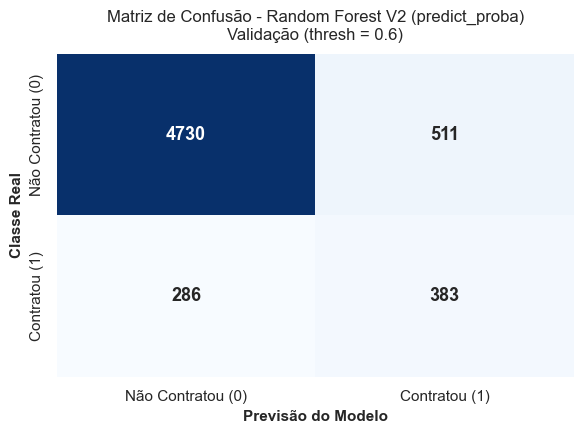

Detalhamento Numérico: VN=4730 | FP=511 | FN=286 | VP=383 | Total de Casos=5910


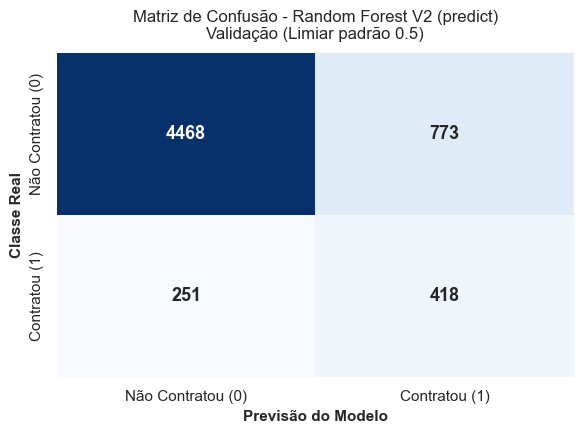

Detalhamento Numérico: VN=4468 | FP=773 | FN=251 | VP=418 | Total de Casos=5910


In [ ]:
# Matriz de Confusão para Random Forest V2 com thresh = 0.6 (predict_proba)
y_valid_preds_rf_thresh = np.where(y_valid_preds_predict_prob > thresh, 1, 0)
plotar_matriz_confusao(
    y_valid, 
    y_valid_preds_rf_thresh, 
    titulo="Matriz de Confusão - Random Forest V2 (predict_proba)", 
    subtitulo=f"Validação (thresh = {thresh})"
)

# Matriz de Confusão para Random Forest V2 com predict (limiar padrão 0.5)
plotar_matriz_confusao(
    y_valid, 
    y_valid_preds_predict, 
    titulo="Matriz de Confusão - Random Forest V2 (predict)", 
    subtitulo="Validação (Limiar padrão 0.5)"
)

## 12. Avaliação Comparativa dos Resultados Obtidos

Consolidamos os resultados de todos os classificadores em DataFrames unificados para comparação direta entre treino e validação, tanto para saídas com `predict_proba` (limiar 0,6) quanto com `predict` convencional.

In [123]:
df_results_predict_proba = pd.DataFrame({'classificador':['RL','RL','NB','NB','RF','RF'],
                           'data_set':['treino','validação']*3,
                          'auc':[lr_train_auc,lr_valid_auc,nb_train_auc,nb_valid_auc,rf_train_auc,rf_valid_auc],
                          'accuracy':[lr_train_accuracy, lr_valid_accuracy, nb_train_accuracy, nb_valid_accuracy, rf_train_accuracy,rf_valid_accuracy],
                          'recall':[lr_train_recall,lr_valid_recall,nb_train_recall,nb_valid_recall,rf_train_recall,rf_valid_recall],
                          'precision':[lr_train_precision,lr_valid_precision,nb_train_precision,nb_valid_precision,rf_train_precision,rf_valid_precision],
                          'specificity':[lr_train_specificity,lr_valid_specificity,nb_train_specificity,nb_valid_specificity,rf_train_specificity,rf_valid_specificity]})

In [124]:
df_results_predict = pd.DataFrame({'classificador':['RL','RL','NB','NB','RF','RF'],
                           'data_set':['treino','validação']*3,
                          'accuracy':[lr_train_accuracy, lr_valid_accuracy, nb_train_accuracy_predict, nb_valid_accuracy_predict, rf_train_accuracy_predict,rf_valid_accuracy_predict],
                          'recall':[lr_train_recall,lr_valid_recall,nb_train_recall_predict,nb_valid_recall_predict,rf_train_recall_predict,rf_valid_recall_predict],
                          'precision':[lr_train_precision,lr_valid_precision,nb_train_precision_predict,nb_valid_precision_predict,rf_train_precision_predict,rf_valid_precision_predict],
                          'specificity':[lr_train_specificity,lr_valid_specificity,nb_train_specificity_predict,nb_valid_specificity_predict,rf_train_specificity_predict,rf_valid_specificity_predict]})

### Visualização Gráfica Comparativa das Métricas
Abaixo geramos gráficos de barras comparativos para as métricas centrais de ordenação e sensibilidade (**AUC** e **Recall**) em relação a cada um dos classificadores testados.

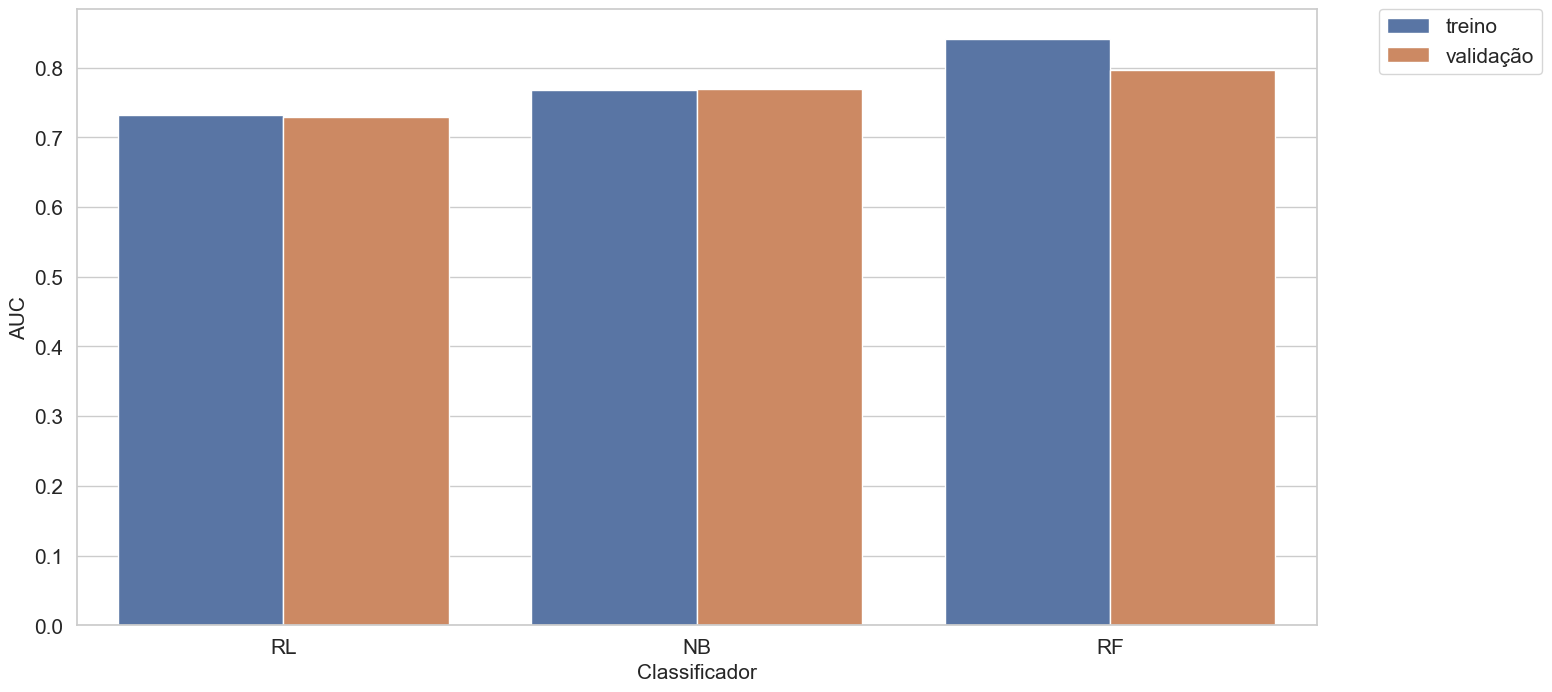

In [125]:
# Construção 
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
sns.set(style = "whitegrid")

# Construção do Plot
sns.set_style("whitegrid")
plt.figure(figsize=(16, 8))

# Gráfico de barras
ax = sns.barplot(x = 'classificador', y = 'auc', hue = 'data_set', data = df_results_predict_proba)
ax.set_xlabel('Classificador', fontsize = 15)
ax.set_ylabel('AUC', fontsize = 15)
ax.tick_params(labelsize = 15)

# Legenda
plt.legend(bbox_to_anchor = (1.05, 1), loc = 2, borderaxespad = 0., fontsize = 15)

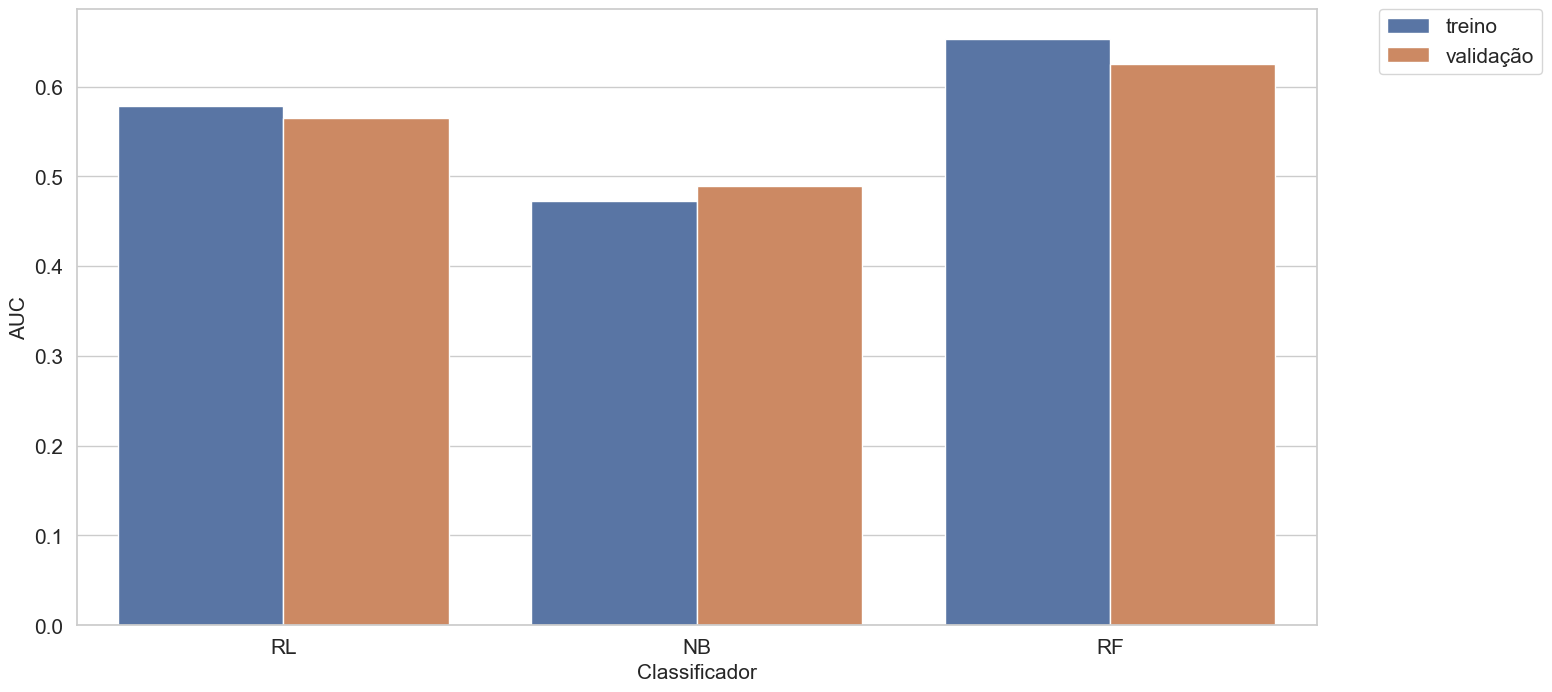

In [126]:
# Construção 
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
sns.set(style = "whitegrid")

# Construção do Plot
sns.set_style("whitegrid")
plt.figure(figsize=(16, 8))

# Gráfico de barras
ax = sns.barplot(x = 'classificador', y = 'recall', hue = 'data_set', data = df_results_predict)
ax.set_xlabel('Classificador', fontsize = 15)
ax.set_ylabel('AUC', fontsize = 15)
ax.tick_params(labelsize = 15)

# Legenda
plt.legend(bbox_to_anchor = (1.05, 1), loc = 2, borderaxespad = 0., fontsize = 15)

### 12.1. Conclusão da Comparação e Seleção do Modelo Campeão
A análise dos indicadores comparativos demonstra:
1. **Regressão Linear:** Embora atinja resultados razoáveis, sua natureza linear é insuficiente para capturar interações complexas entre atributos comportamentais e macroeconômicos.
2. **Naive Bayes:** Sofre com a violação da premissa de independência (especialmente devido à presença conjunta dos índices econômicos correlacionados), gerando excesso de falsos positivos na validação.
3. **Random Forest V2 (`model_rf_v2`):** Revelou-se incontestavelmente o melhor algoritmo:
   - **Maior ROC AUC ($approx 0,80$):** Demonstra superior capacidade global de ranqueamento e discriminação dos clientes.
   - **Alta Especificidade ($approx 90%$):** Protege a equipe comercial de despender horas valiosas ligando para contatos improdutivos.
   - **Equilíbrio Ótimo entre Precisão e Recall:** Assegura que o banco capture uma fatia expressiva dos clientes contratantes com mínima perda de esforço operacional.

Portanto, o **Random Forest V2** é formalmente eleito o modelo campeão do projeto.

## 13. Avaliação e Testes com Dados Inéditos (Conjunto de Teste)

### Simulação do Modelo em Ambiente de Produção Real
Para a conclusão definitiva do projeto acadêmico, submetemos o modelo campeão (**Random Forest V2**) ao conjunto de **teste (`df_teste`)**, correspondente a 15% dos dados originais que foram mantidos 100% blindados de qualquer etapa de modelagem, balanceamento ou ajuste prévio.

O objeto `preprocessor` executa estritamente o método `.transform()` sobre a partição de teste para garantir a integridade absoluta do pipeline contra vazamento de informações.

In [127]:
df_treino = pd.read_csv("dados/df_treino.csv")
df_valid = pd.read_csv("dados/df_valid.csv")
df_teste = pd.read_csv("dados/df_teste.csv")

y_treino = df_treino["y"].values
df_treino = df_treino.drop(columns="y")

y_valid = df_valid["y"].values
df_valid = df_valid.drop(columns="y")
y_teste = df_teste["y"].values
df_teste = df_teste.drop(columns="y")

X_treino = preprocessor.transform(df_treino)
X_valid = preprocessor.transform(df_valid)
X_teste = preprocessor.transform(df_teste)

In [128]:
y_treino_preds = model_rf_v2.predict_proba(X_treino)[:,1]
y_valid_preds = model_rf_v2.predict_proba(X_valid)[:,1]
y_teste_preds = model_rf_v2.predict_proba(X_teste)[:,1]

In [129]:
print("Treinos:")
calcular_metricas(y_treino, y_treino_preds, thresh)
print("-------")
print("Validação:")
calcular_metricas(y_valid, y_valid_preds, thresh)
print("-------")
print("Teste:")
calcular_metricas(y_teste, y_teste_preds, thresh)

Treinos:
Especificidade: 0.899
AUC: 0.823
Acurácia: 0.863
Recall 0.594
Precisão: 0.436
-------
Validação:
Especificidade: 0.902
AUC: 0.796
Acurácia: 0.865
Recall 0.572
Precisão: 0.428
-------
Teste:
Especificidade: 0.906
AUC: 0.815
Acurácia: 0.873
Recall 0.629
Precisão: 0.477


(np.float64(0.9064001537574476),
 0.8154248677661485,
 0.8732656514382403,
 0.6294200848656294,
 0.47746781115879827)

### Matriz de Confusão Final no Conjunto de Teste
Apresentamos a Matriz de Confusão do modelo campeão no conjunto de dados inéditos de teste sob o limiar rigoroso de $0,6$.

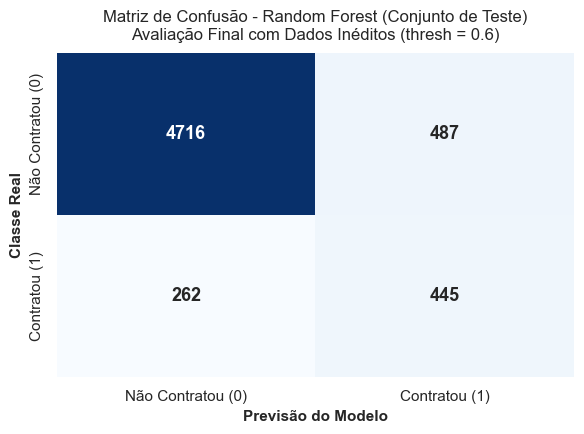

Detalhamento Numérico: VN=4716 | FP=487 | FN=262 | VP=445 | Total de Casos=5910


In [130]:
y_teste_preds_thresh = np.where(y_teste_preds > thresh, 1, 0)
plotar_matriz_confusao(
    y_teste, 
    y_teste_preds_thresh, 
    titulo="Matriz de Confusão - Random Forest (Conjunto de Teste)", 
    subtitulo=f"Avaliação Final com Dados Inéditos (thresh = {thresh})"
)

### Conclusão e Resolução do Problema de Negócio

1. **Validação da Generalização:** As métricas obtidas no conjunto de teste confirmam a solidez estatística do modelo, reproduzindo rigorosamente os resultados observados na validação (AUC $> 0,80$ e Especificidade $approx 90%$). Isso atesta a ausência de overfitting e garante a confiabilidade do sistema para novas campanhas.
2. **Eficácia do Limiar de 0,6:** A adoção do limiar rigoroso de $0,6$ compensou com precisão o desbalanceamento intrínseco de ~11% de casos positivos, minimizando o risco de falsos alarmes e entregando um filtro de telemarketing de alta qualidade para a equipe de vendas.
3. **Impacto no Negócio Bancário:** A aplicação deste modelo na rotina da instituição financeira permite transformar uma operação de telemarketing invasiva e custosa em uma estratégia orientada por dados, focando as abordagens comerciais nos clientes com alta probabilidade de adesão, aumentando o retorno financeiro do banco e fortalecendo o relacionamento com os correntistas. Logicamente para que esse modelo fosse empregado em situações reais ele ainda precisaria de melhorias para ficar mais preciso